# Лабораторная работа №2
## Виртуальный датчик концентрации продукта обжига

**Задача.** По минутной телеметрии печи (16 каналов) и нерегулярным лабораторным замерам
прогнозировать концентрацию целевого продукта в текущий момент. Лабораторный результат
поступает с задержкой 10-15 минут, поэтому в признаках используется только история
целевого показателя, но не его текущее значение.

**Данные.**
- `data_train.csv` - минутная телеметрия за 8 месяцев.
- `target_train.csv` - лабораторные замеры (в среднем каждые 2 часа).
- `data_test_small.csv`, `target_test_small.csv` - отложенный тестовый период.

**Структура решения.**
1. EDA и синхронизация источников.
2. Инжиниринг временных признаков.
3. Модели и оценка качества.
4. Выводы и интерпретация.

In [1]:
%matplotlib inline

import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.max_open_warning": 0, "axes.titlesize": 11})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

In [2]:
# Исходные CSV лежат рядом с ноутбуком, в корне папки lab2.
DATA_DIR = Path(".")
print("DATA_DIR =", DATA_DIR.resolve())

DATA_DIR = /home/exg0rd/Desktop/pred_anal/repo


## 2.1. Разведочный анализ и синхронизация данных

Сначала проверяем структуру, пропуски, дубликаты и временные интервалы. Затем совмещаем
телеметрию и лабораторные замеры. Отдельно исследуем задержку: корреляцию целевого
показателя с телеметрией при сдвигах от -120 до +120 минут.

In [3]:
def read_telemetry(path):
    df = pd.read_csv(path, parse_dates=["datetime"])
    df = df.sort_values("datetime").drop_duplicates("datetime")
    return df.set_index("datetime")

train_raw = read_telemetry(DATA_DIR / "data_train.csv")
test_raw = read_telemetry(DATA_DIR / "data_test_small.csv")

target_train = (
    pd.read_csv(DATA_DIR / "target_train.csv", parse_dates=["Дата"])
    .rename(columns={"Дата": "datetime"})
    .sort_values("datetime")
    .drop_duplicates("datetime")
    .set_index("datetime")
)
target_test = (
    pd.read_csv(DATA_DIR / "target_test_small.csv", parse_dates=["Дата"])
    .rename(columns={"Дата": "datetime"})
    .sort_values("datetime")
    .drop_duplicates("datetime")
    .set_index("datetime")
)

summary = pd.DataFrame({
    "train": [train_raw.shape[0], train_raw.shape[1], train_raw.index.min(), train_raw.index.max()],
    "test": [test_raw.shape[0], test_raw.shape[1], test_raw.index.min(), test_raw.index.max()],
    "target_train": [len(target_train), target_train.shape[1], target_train.index.min(), target_train.index.max()],
    "target_test": [len(target_test), target_test.shape[1], target_test.index.min(), target_test.index.max()],
}, index=["rows", "cols", "start", "end"])
display(summary)
display(target_train.head(3))

,train,test,target_train,target_test
rows,317998,39747,1773,318
cols,16,16,1,1
start,2019-03-01 00:01:00,2019-10-07 19:59:00,2019-03-13 17:00:00,2019-10-07 23:00:00
end,2019-10-07 19:58:00,2019-11-04 10:25:00,2019-10-07 21:00:00,2019-11-04 09:00:00


,target
datetime,
2019-03-13 17:00:00,0.123711
2019-03-13 21:00:00,0.319588
2019-03-14 01:00:00,0.255155


In [4]:
# Доли пропусков по каналам: 12-15 почти пустые, исключаем их из модели.
missing = pd.DataFrame({
    "train_missing": train_raw.isna().mean(),
    "test_missing": test_raw.isna().mean(),
}).sort_values("train_missing", ascending=False)
display((missing * 100).round(3).T)

all_telemetry = [c for c in train_raw.columns if c.startswith("telemetry_")]
sparse_cols = missing.index[missing.train_missing > 0.5].tolist()
telemetry_cols = [c for c in all_telemetry if c not in sparse_cols]
print("Рабочие каналы:", telemetry_cols)
print("Исключены как почти пустые:", sparse_cols)

,telemetry_12,telemetry_13,telemetry_14,telemetry_15,telemetry_4,telemetry_0,telemetry_5,telemetry_1,telemetry_2,telemetry_3,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11
train_missing,99.341,99.341,99.341,99.341,0.042,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005
test_missing,99.200,99.200,99.200,99.200,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003,0.003


Рабочие каналы: ['telemetry_0', 'telemetry_1', 'telemetry_2', 'telemetry_3', 'telemetry_4', 'telemetry_5', 'telemetry_6', 'telemetry_7', 'telemetry_8', 'telemetry_9', 'telemetry_10', 'telemetry_11']
Исключены как почти пустые: ['telemetry_12', 'telemetry_13', 'telemetry_14', 'telemetry_15']


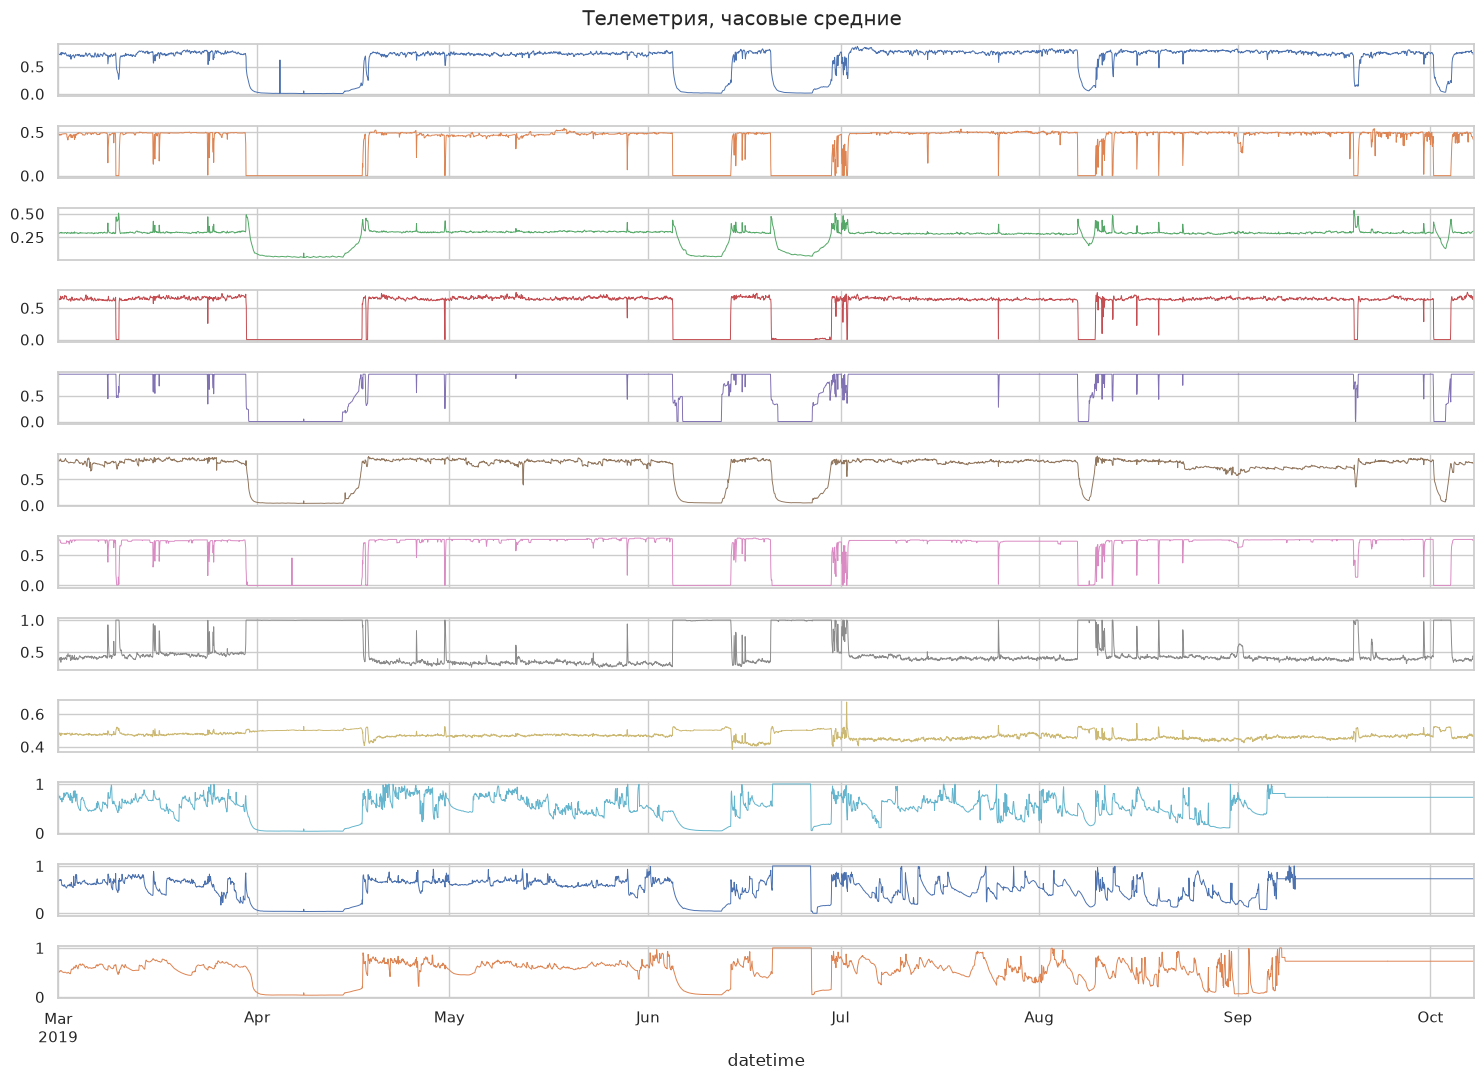

In [5]:
# Обзор телеметрии: часовые средние за весь период.
train_raw[telemetry_cols].resample("1h").mean().plot(
    subplots=True, figsize=(15, 11), sharex=True, lw=0.7, legend=False,
    title="Телеметрия, часовые средние"
)
plt.tight_layout()
plt.show()

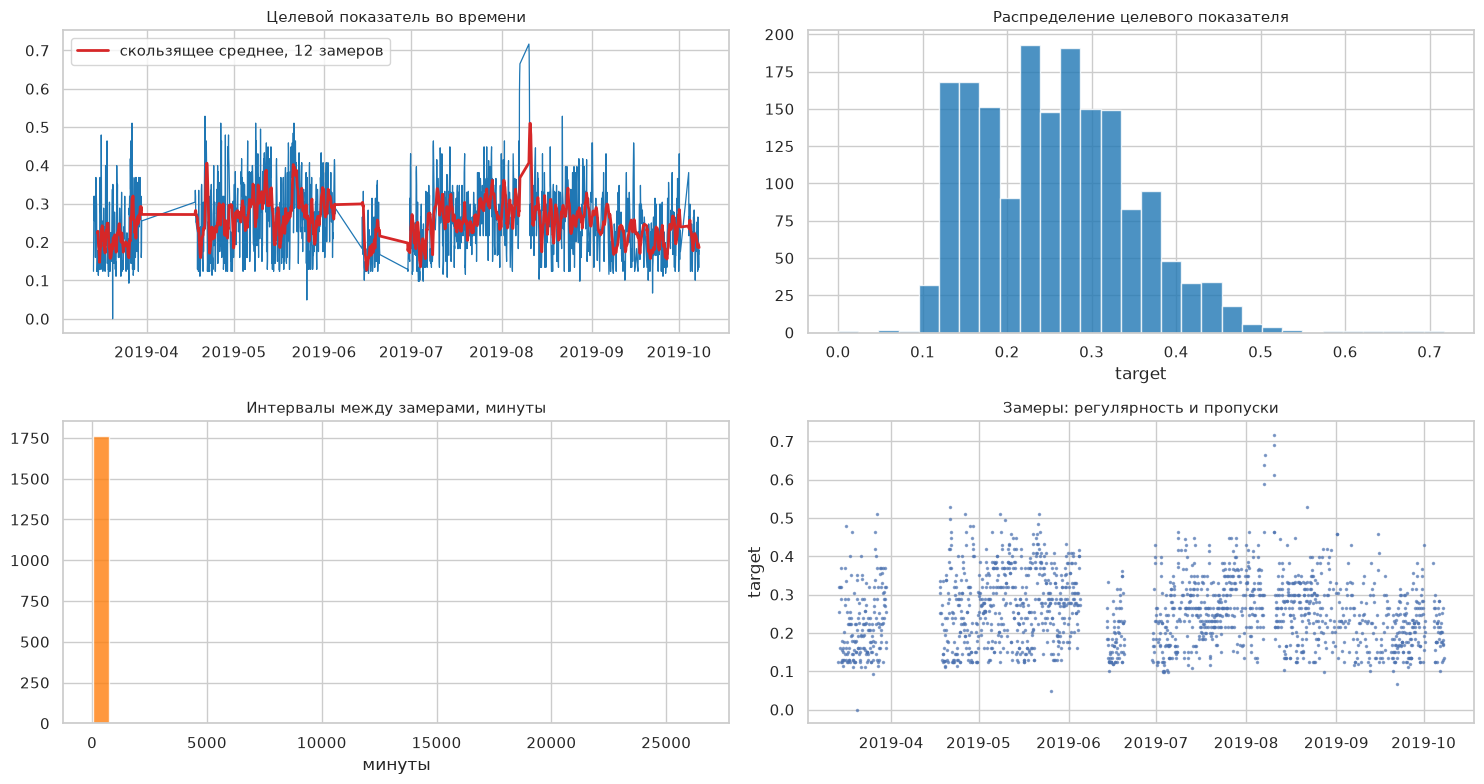

Интервалы, топ-5:
datetime
120.0    1570
240.0     184
60.0        4
420.0       2
90.0        1
Name: count, dtype: int64

Описательные статистики target:


,count,mean,std,min,25%,50%,75%,max
target,1773.0,0.254272,0.092208,0.0,0.175258,0.247423,0.314433,0.716495


Уникальных значений target: 109


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

axes[0, 0].plot(target_train.index, target_train["target"], lw=0.9, color="tab:blue")
axes[0, 0].plot(target_train.index, target_train["target"].rolling(12).mean(),
                lw=2, color="tab:red", label="скользящее среднее, 12 замеров")
axes[0, 0].set_title("Целевой показатель во времени")
axes[0, 0].legend()

axes[0, 1].hist(target_train["target"], bins=30, color="tab:blue", alpha=0.8)
axes[0, 1].set_title("Распределение целевого показателя")
axes[0, 1].set_xlabel("target")

intervals = target_train.index.to_series().diff().dt.total_seconds().div(60).dropna()
axes[1, 0].hist(intervals, bins=40, color="tab:orange", alpha=0.8)
axes[1, 0].set_title("Интервалы между замерами, минуты")
axes[1, 0].set_xlabel("минуты")

axes[1, 1].plot(target_train.index, target_train["target"], ".", ms=3, alpha=0.6)
axes[1, 1].set_title("Замеры: регулярность и пропуски")
axes[1, 1].set_ylabel("target")

plt.tight_layout()
plt.show()

print("Интервалы, топ-5:")
print(intervals.value_counts().head())
print("\nОписательные статистики target:")
display(target_train["target"].describe().to_frame().T)
print("Уникальных значений target:", target_train["target"].nunique())

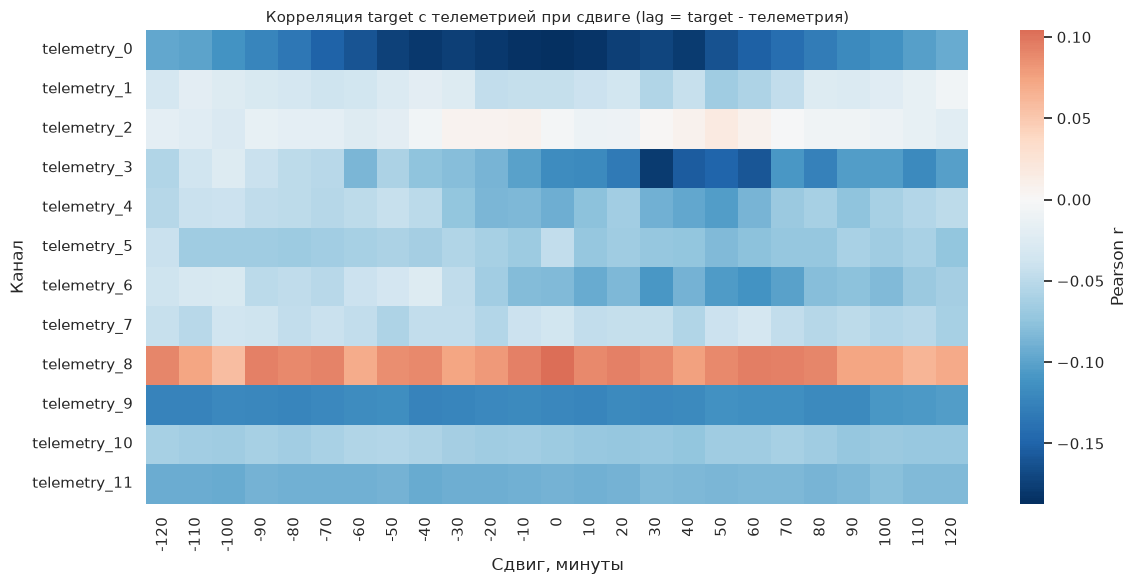

,best_lag_min,max_abs_corr
telemetry_0,0,0.187
telemetry_3,30,0.179
telemetry_9,-110,0.125
telemetry_6,60,0.112
telemetry_4,50,0.104
telemetry_8,0,0.104
telemetry_11,-100,0.094
telemetry_5,50,0.083
telemetry_10,40,0.074
telemetry_1,50,0.066


Корреляции при lag=0:


,telemetry_0,telemetry_9,telemetry_3,telemetry_8,telemetry_4,telemetry_11,telemetry_6,telemetry_10,telemetry_5,telemetry_1,telemetry_7,telemetry_2
0,-0.187,-0.122,-0.118,0.104,-0.091,-0.087,-0.082,-0.069,-0.046,-0.044,-0.036,-0.003


In [7]:
# Оценка задержки: корреляция target с телеметрией при сдвиге lag минут.
def lag_corr(telemetry, target, lag_minutes):
    idx = target.index - pd.Timedelta(minutes=lag_minutes)
    shifted = telemetry.reindex(idx, method="nearest", tolerance=pd.Timedelta("1min"))
    shifted.index = target.index
    return shifted[telemetry_cols].corrwith(target["target"])

lags = np.arange(-120, 121, 10)
corr_by_lag = pd.DataFrame({lag: lag_corr(train_raw, target_train, lag) for lag in lags}).T

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(corr_by_lag.T, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Корреляция target с телеметрией при сдвиге (lag = target - телеметрия)")
ax.set_xlabel("Сдвиг, минуты")
ax.set_ylabel("Канал")
plt.tight_layout()
plt.show()

best = corr_by_lag.abs().idxmax()
best_corr = corr_by_lag.abs().max()
table = pd.DataFrame({"best_lag_min": best, "max_abs_corr": best_corr}).sort_values(
    "max_abs_corr", ascending=False
)
display(table.round(3))
print("Корреляции при lag=0:")
display(corr_by_lag.loc[0].sort_values(key=np.abs, ascending=False).round(3).to_frame().T)

### Выводы по 2.1

- Телеметрия содержит 12 информативных минутных каналов; `telemetry_12..15` заполнены
  менее чем на 1% и исключены.
- Пропуски в рабочих каналах менее 0.1%, дубликаты меток времени удалены. Редкие пропуски
  интерполируются по времени с ограничением 5 минут; грубые выбросы не удаляются, так как
  в производственном процессе они могут быть реальными событиями.
- Целевой показатель измеряется в основном каждые 2 часа (иногда 4 часа), всего 1773
  наблюдения. Распределение правоскошенное, значения лежат в диапазоне примерно 0-0.72
  и образуют дискретную сетку с шагом `1/97`.
- Мгновенная линейная связь телеметрии с target слабая: максимальный |r| около 0.19.
  При этом target заметно автокоррелирован (r ~ 0.55 на соседних замерах), поэтому история
  целевого показателя обязательна.
- Лабораторный результат приходит с задержкой 10-15 минут. В текущий момент известны
  телеметрия до `t` и предыдущие лабораторные замеры, но не `target(t)`. Это ограничение
  учтено в признаках.

## 2.2. Инжиниринг признаков для временных рядов

Формируем вектор признаков на каждый момент лабораторного замера:

- сырые значения телеметрии со сдвигами 0, 5, 10, 15, 30, 60 и 120 минут;
- скользящие `mean/std/min/max` по окнам 5-240 минут;
- приращения за 5, 15 и 60 минут;
- календарные признаки (час, день недели, циклические кодировки часа);
- лаги и скользящие статистики самого target, но только по прошлым замерам.

Для теста история target склеивается с train: предыдущий замер к моменту `t` уже известен,
поэтому это не утечка. Текущий замер в признаки не попадает.

In [8]:
SPARSE_COLS = sparse_cols

def prepare_telemetry(df):
    # Регулярная минутная сетка + короткая интерполяция пропусков.
    out = df.drop(columns=[c for c in df.columns if c in SPARSE_COLS]).copy()
    out = out.asfreq("1min")
    out = out.interpolate(method="time", limit=5).ffill().bfill()
    return out

train_tele = prepare_telemetry(train_raw)
test_tele = prepare_telemetry(test_raw)
print(train_tele.shape, test_tele.shape)
print("Пропуски после подготовки:", int(train_tele.isna().sum().sum()), int(test_tele.isna().sum().sum()))

(317998, 12) (39747, 12)
Пропуски после подготовки: 0 0


In [9]:
SHIFTS = (0, 5, 10, 15, 30, 60, 120)
WINDOWS = (5, 15, 30, 60, 120, 240)


def build_features(telemetry, target_history, eval_index):
    # Признаки телеметрии считаются только из данных до соответствующего момента.
    cols = {}

    for shift in SHIFTS:
        part = telemetry.reindex(
            eval_index - pd.Timedelta(minutes=shift),
            method="nearest",
            tolerance=pd.Timedelta("1min"),
        )
        part.index = eval_index
        for col in telemetry.columns:
            cols[f"{col}_lag{shift}"] = part[col]

    for window in WINDOWS:
        rolling = telemetry.rolling(f"{window}min", min_periods=max(2, window // 5))
        for stat in ("mean", "std", "min", "max"):
            part = getattr(rolling, stat)().reindex(
                eval_index, method="nearest", tolerance=pd.Timedelta("1min")
            )
            part.index = eval_index
            for col in telemetry.columns:
                cols[f"{col}_r{window}_{stat}"] = part[col]

    for shift in (5, 15, 60):
        now = telemetry.reindex(eval_index, method="nearest", tolerance=pd.Timedelta("1min"))
        now.index = eval_index
        before = telemetry.reindex(
            eval_index - pd.Timedelta(minutes=shift),
            method="nearest",
            tolerance=pd.Timedelta("1min"),
        )
        before.index = eval_index
        for col in telemetry.columns:
            cols[f"{col}_d{shift}"] = now[col] - before[col]

    features = pd.DataFrame(cols, index=eval_index)
    features["hour"] = eval_index.hour
    features["dow"] = eval_index.dayofweek
    features["hour_sin"] = np.sin(2 * np.pi * eval_index.hour / 24)
    features["hour_cos"] = np.cos(2 * np.pi * eval_index.hour / 24)

    # История target: только значения до текущего замера.
    target_series = target_history["target"].sort_index()
    for k in (1, 2, 3, 6, 12):
        features[f"tgt_prev{k}"] = target_series.shift(k).reindex(
            eval_index, method="ffill"
        )
    shifted_target = target_series.shift(1)
    for hours in (2, 4, 6, 12, 24):
        features[f"tgt_mean_{hours}h"] = shifted_target.rolling(
            f"{hours}h"
        ).mean().reindex(eval_index, method="ffill")
    features["tgt_diff1"] = features["tgt_prev1"] - features["tgt_prev2"]
    return features


X_train = build_features(train_tele, target_train, target_train.index)
target_history_full = pd.concat([target_train, target_test]).sort_index()
X_test = build_features(test_tele, target_history_full, target_test.index)

y_train = target_train["target"]
y_test = target_test["target"]

# Оставляем только признаки, доступные в train; пропуски заполняем медианой train.
X_train = X_train.loc[:, X_train.notna().any()]
X_test = X_test[X_train.columns]
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Признаков target-истории:", sum(c.startswith("tgt_") for c in X_train.columns))
display(X_train[["tgt_prev1", "tgt_mean_4h", "telemetry_0_lag0"]].head(3))

X_train: (1773, 423) | X_test: (318, 423)
Признаков target-истории: 11


,tgt_prev1,tgt_mean_4h,telemetry_0_lag0
datetime,,,
2019-03-13 17:00:00,0.247423,0.248711,0.786148
2019-03-13 21:00:00,0.123711,0.123711,0.776599
2019-03-14 01:00:00,0.319588,0.319588,0.783254


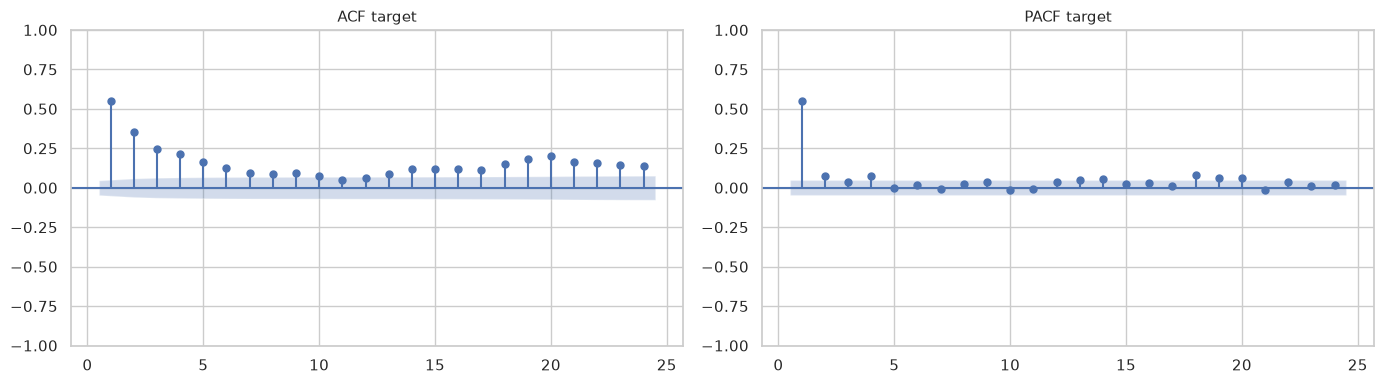

Автокорреляция target:
  lag  1 наблюдений: +0.550
  lag  2 наблюдений: +0.353
  lag  3 наблюдений: +0.246
  lag  6 наблюдений: +0.128
  lag 12 наблюдений: +0.062


In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(target_train["target"], lags=24, ax=axes[0], zero=False)
axes[0].set_title("ACF target")
plot_pacf(target_train["target"], lags=24, ax=axes[1], zero=False, method="ywm")
axes[1].set_title("PACF target")
plt.tight_layout()
plt.show()

print("Автокорреляция target:")
for lag in (1, 2, 3, 6, 12):
    print(f"  lag {lag:2d} наблюдений: {target_train['target'].autocorr(lag):+.3f}")

In [11]:
# Отбор признаков: F-тест и корреляция с target.
from sklearn.feature_selection import f_regression

f_scores, _ = f_regression(X_train, y_train)
f_table = pd.Series(f_scores, index=X_train.columns).sort_values(ascending=False)

corr_table = X_train.corrwith(y_train).abs().sort_values(ascending=False)

print("Топ-20 признаков по F-тесту:")
display(f_table.head(20).round(2).to_frame("F"))
print("Топ-20 признаков по |corr|:")
display(corr_table.head(20).round(3).to_frame("|corr|"))

Топ-20 признаков по F-тесту:


,F
tgt_prev1,767.71
tgt_mean_2h,765.92
tgt_mean_4h,620.37
tgt_mean_6h,522.97
tgt_mean_12h,374.77
tgt_prev2,251.78
tgt_mean_24h,235.59
tgt_prev3,114.37
tgt_diff1,80.46
telemetry_0_r60_max,75.69


Топ-20 признаков по |corr|:


,|corr|
tgt_prev1,0.550
tgt_mean_2h,0.549
tgt_mean_4h,0.509
tgt_mean_6h,0.477
tgt_mean_12h,0.418
tgt_prev2,0.353
tgt_mean_24h,0.343
tgt_prev3,0.246
tgt_diff1,0.208
telemetry_0_r60_max,0.202


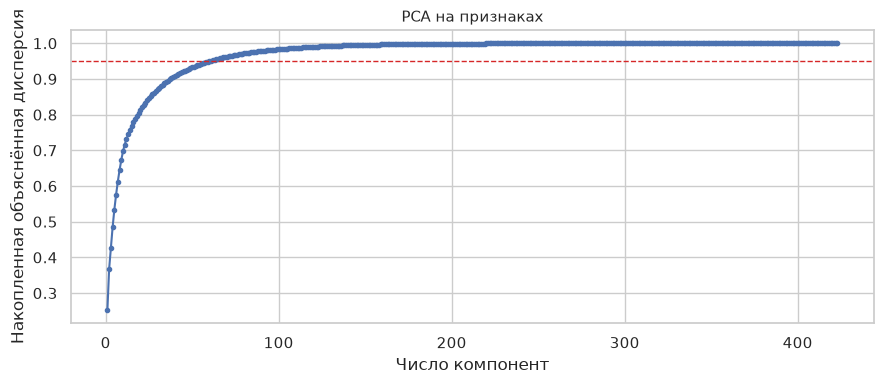

Компонент для 90% дисперсии: 38
Компонент для 95% дисперсии: 61


In [12]:
# PCA: проверяем, сколько компонент нужно для сжатия пространства признаков.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_train)
pca = PCA(random_state=RANDOM_STATE).fit(X_scaled)
explained = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(explained) + 1), explained, marker=".")
ax.axhline(0.95, color="tab:red", ls="--", lw=1)
ax.set_xlabel("Число компонент")
ax.set_ylabel("Накопленная объяснённая дисперсия")
ax.set_title("PCA на признаках")
plt.tight_layout()
plt.show()

print("Компонент для 90% дисперсии:", int(np.searchsorted(explained, 0.90) + 1))
print("Компонент для 95% дисперсии:", int(np.searchsorted(explained, 0.95) + 1))

### Выводы по 2.2

- Получено 423 признака. Основной вклад в линейную связь дают скользящие средние и лаги
  target, затем каналы `telemetry_0`, `telemetry_3`, `telemetry_6` и их скользящие максимумы.
- PCA сжимает пространство до 38 компонент для 90% дисперсии и до 61 для 95%.
  Однако компоненты теряют физическую интерпретацию, поэтому в финале используем
  отбор признаков по F-тесту.
- Признаки `tgt_mean_*` и `tgt_prev*` описывают инерцию процесса, а признаки телеметрии -
  текущее состояние печи. Такая комбинация соответствует идее виртуального датчика:
  лабораторный замер уточняет уровень, телеметрия объясняет отклонения.

## 2.3. Прогнозные модели

Рассматриваем три класса моделей:

1. **Ridge-регрессия** - линейная модель с L2-регуляризацией для большого числа
   коррелирующих признаков; хорошо интерпретируется.
2. **ExtraTrees** - нелинейный ансамбль деревьев, устойчив к масштабу и выбросам,
   моделирует взаимодействия признаков.
3. **HistGradientBoosting** - градиентный бустинг для табличных данных, эффективен
   на средних выборках, поддерживает пропуски и нелинейности.

Дополнительно считаем две базовые стратегии: последний известный замер (persistence)
и скользящее среднее последних замеров.

**Что точно не подходит.**
- ARIMA/SARIMA в чистом виде: target нерегулярен, прогноз строится на одной переменной без
  телеметрии; экзогенные высокочастотные каналы теряются.
- Prophet: рассчитан на регулярный ряд и тренд-сезонность, а не на краткосрочную
  динамику процесса по 12 датчикам.
- LSTM/TCN/Transformer: всего 1773 размеченных точки, глубокие модели будут переобучаться,
  требуют много вычислений и хуже интерпретируются.
- VAR/VECM: требует регулярного совместного ряда, а target наблюдается только раз в 2 часа.

In [13]:
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def wape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return np.abs(y_true - y_pred).sum() / np.abs(y_true).sum()


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE, %": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "WAPE, %": wape(y_true, y_pred) * 100,
    }

In [14]:
# Подбор k и alpha для Ridge по TimeSeriesSplit только на train.
ridge_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_regression)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])

param_grid = {
    "select__k": [40, 60, 80, 120],
    "ridge__alpha": [10, 30, 100, 300],
}
tscv = TimeSeriesSplit(n_splits=5)
grid = GridSearchCV(
    ridge_pipe,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

best_ridge = grid.best_estimator_
selected_mask = best_ridge.named_steps["select"].get_support()
selected_cols = X_train.columns[selected_mask]
print("Лучшие параметры Ridge:", grid.best_params_)
print("CV MAE:", round(-grid.best_score_, 4))
print("Отобрано признаков:", len(selected_cols))

Лучшие параметры Ridge: {'ridge__alpha': 100, 'select__k': 40}
CV MAE: 0.0617
Отобрано признаков: 40


In [15]:
X_train_sel = X_train[selected_cols]
X_test_sel = X_test[selected_cols]

extra_trees = ExtraTreesRegressor(
    n_estimators=600,
    max_depth=12,
    min_samples_leaf=3,
    max_features=0.4,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
hgb = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_iter=600,
    learning_rate=0.03,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    l2_regularization=5.0,
    random_state=RANDOM_STATE,
)

models = {
    "Ridge (CV)": best_ridge,
    "ExtraTrees": extra_trees,
    "HistGradientBoosting": hgb,
}

predictions = {}
timings = {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train_sel, y_train)
    predictions[name] = model.predict(X_test_sel)
    timings[name] = time.perf_counter() - t0

# Базовые стратегии.
predictions["Persistence"] = X_test["tgt_prev1"].to_numpy()
predictions["Скользящее среднее"] = X_test["tgt_mean_4h"].to_numpy()
timings["Persistence"] = 0.0
timings["Скользящее среднее"] = 0.0

rows = []
for name, pred in predictions.items():
    row = regression_metrics(y_test, pred)
    row["fit, сек"] = timings[name]
    rows.append(pd.Series(row, name=name))
metrics_df = pd.DataFrame(rows)
display(metrics_df.round(4).sort_values("WAPE, %"))

,MAE,RMSE,"MAPE, %","WAPE, %","fit, сек"
Ridge (CV),0.0518,0.0667,28.4807,24.6868,0.0521
HistGradientBoosting,0.0524,0.0680,27.7238,24.9705,12.3991
ExtraTrees,0.0537,0.0684,29.8767,25.6191,4.9433
Скользящее среднее,0.0554,0.0746,27.9104,26.3972,0.0000
Persistence,0.0595,0.0801,29.7174,28.3682,0.0000


In [16]:
# Направление изменения: сравниваем знак приращения относительно предыдущего замера.
def direction_accuracy(y_true, y_pred, previous):
    actual_delta = np.asarray(y_true) - np.asarray(previous)
    pred_delta = np.asarray(y_pred) - np.asarray(previous)
    mask = np.abs(actual_delta) > 1e-12
    return np.mean(np.sign(actual_delta[mask]) == np.sign(pred_delta[mask]))


previous = X_test["tgt_prev1"].to_numpy()
direction = {
    name: direction_accuracy(y_test.to_numpy(), pred, previous)
    for name, pred in predictions.items()
}
display(pd.Series(direction, name="Direction accuracy").sort_values(ascending=False).to_frame().round(3))

,Direction accuracy
ExtraTrees,0.712
HistGradientBoosting,0.709
Ridge (CV),0.689
Скользящее среднее,0.599
Persistence,0.000


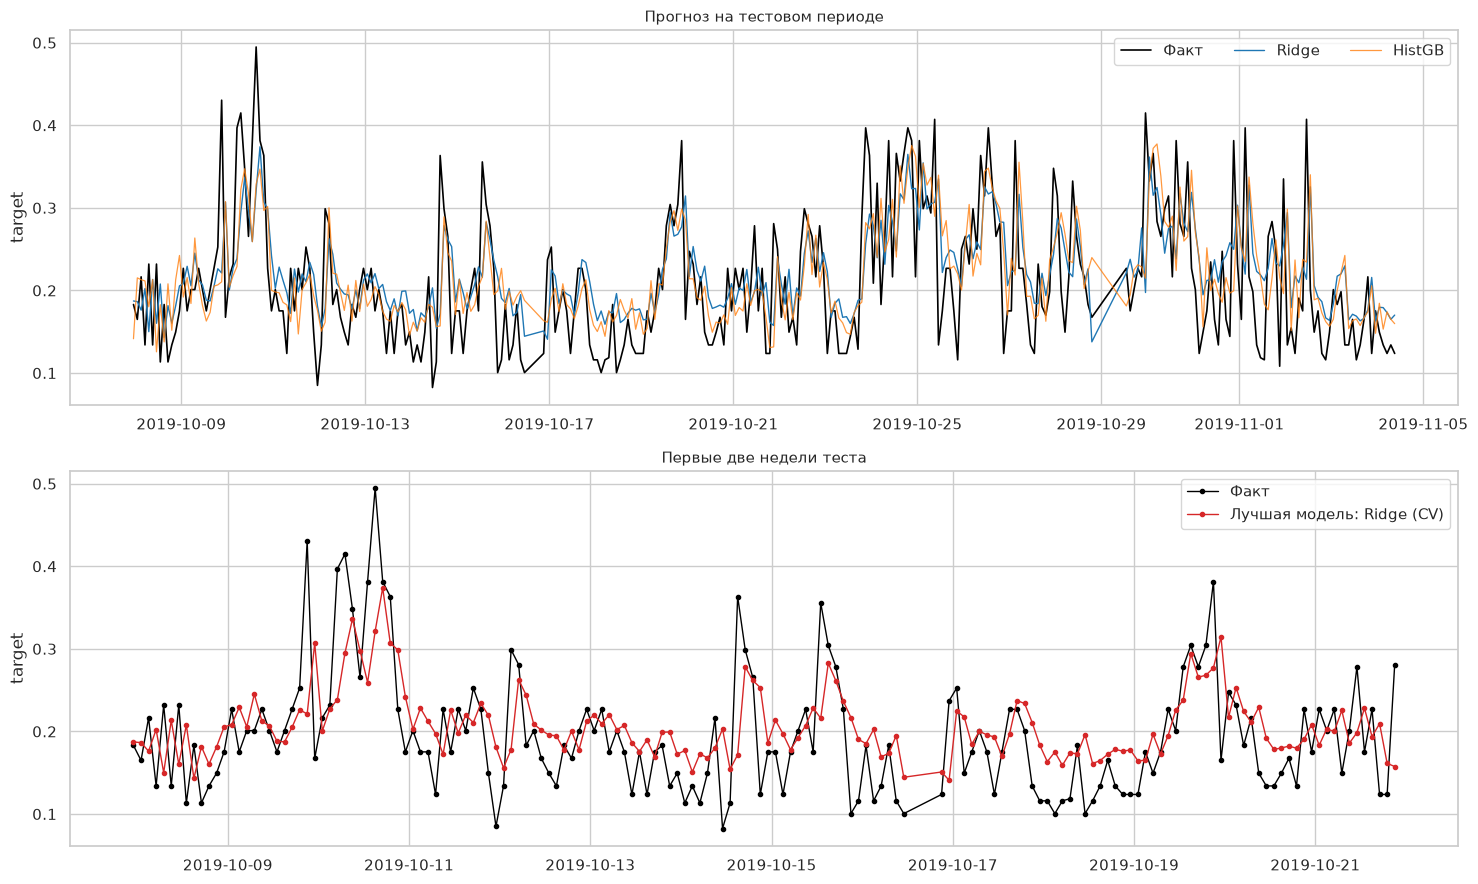

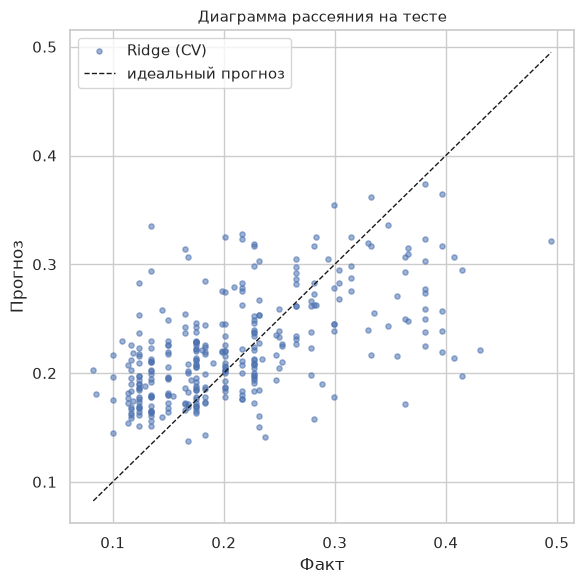

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=False)
best_name = metrics_df["WAPE, %"].idxmin()
best_pred = predictions[best_name]

axes[0].plot(y_test.index, y_test.values, color="black", lw=1.2, label="Факт")
axes[0].plot(y_test.index, predictions["Ridge (CV)"], color="tab:blue", lw=1.0,
             label="Ridge")
axes[0].plot(y_test.index, predictions["HistGradientBoosting"], color="tab:orange",
             lw=0.9, alpha=0.8, label="HistGB")
axes[0].set_title("Прогноз на тестовом периоде")
axes[0].set_ylabel("target")
axes[0].legend(ncol=3)

zoom = y_test.index < (y_test.index.min() + pd.Timedelta(days=14))
axes[1].plot(y_test.index[zoom], y_test.values[zoom], "o-", ms=3, color="black",
             lw=1, label="Факт")
axes[1].plot(y_test.index[zoom], best_pred[zoom], "o-", ms=3, color="tab:red",
             lw=1, label=f"Лучшая модель: {best_name}")
axes[1].set_title("Первые две недели теста")
axes[1].set_ylabel("target")
axes[1].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_pred, s=14, alpha=0.55, label=best_name)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
ax.plot(lims, lims, "k--", lw=1, label="идеальный прогноз")
ax.set_xlabel("Факт")
ax.set_ylabel("Прогноз")
ax.set_title("Диаграмма рассеяния на тесте")
ax.legend()
plt.tight_layout()
plt.show()

,тест,статистика,p-value
0,Jarque-Bera (нормальность),48.8030,0.0000
1,Ljung-Box lag=6,9.2726,0.1588
2,Ljung-Box lag=12,12.5182,0.4050
3,Breusch-Pagan (гетероскедастичность),12.2398,0.0005


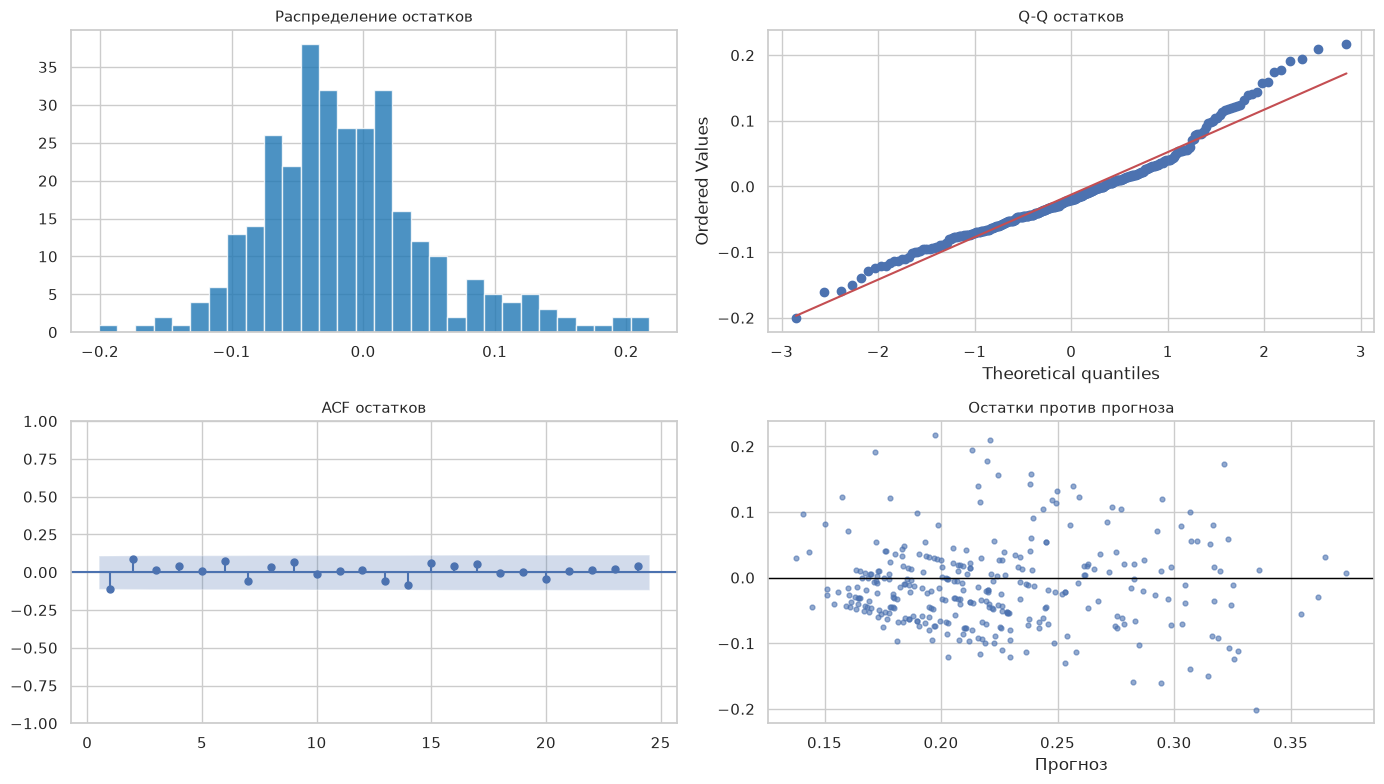

In [18]:
# Анализ остатков лучшей модели на тесте.
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

residuals = y_test.to_numpy() - best_pred

jb_stat, jb_p, _, _ = jarque_bera(residuals)
lb = acorr_ljungbox(residuals, lags=[6, 12], return_df=True)
bp = het_breuschpagan(residuals, np.column_stack([np.ones(len(best_pred)), best_pred]))

diag = pd.DataFrame({
    "тест": ["Jarque-Bera (нормальность)", "Ljung-Box lag=6", "Ljung-Box lag=12",
             "Breusch-Pagan (гетероскедастичность)"],
    "статистика": [jb_stat, lb.loc[6, "lb_stat"], lb.loc[12, "lb_stat"], bp[0]],
    "p-value": [jb_p, lb.loc[6, "lb_pvalue"], lb.loc[12, "lb_pvalue"], bp[1]],
})
display(diag.round(4))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].hist(residuals, bins=30, color="tab:blue", alpha=0.8)
axes[0, 0].set_title("Распределение остатков")

stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q остатков")

plot_acf(residuals, lags=24, ax=axes[1, 0], zero=False)
axes[1, 0].set_title("ACF остатков")

axes[1, 1].scatter(best_pred, residuals, s=12, alpha=0.6)
axes[1, 1].axhline(0, color="black", lw=1)
axes[1, 1].set_title("Остатки против прогноза")
axes[1, 1].set_xlabel("Прогноз")

plt.tight_layout()
plt.show()

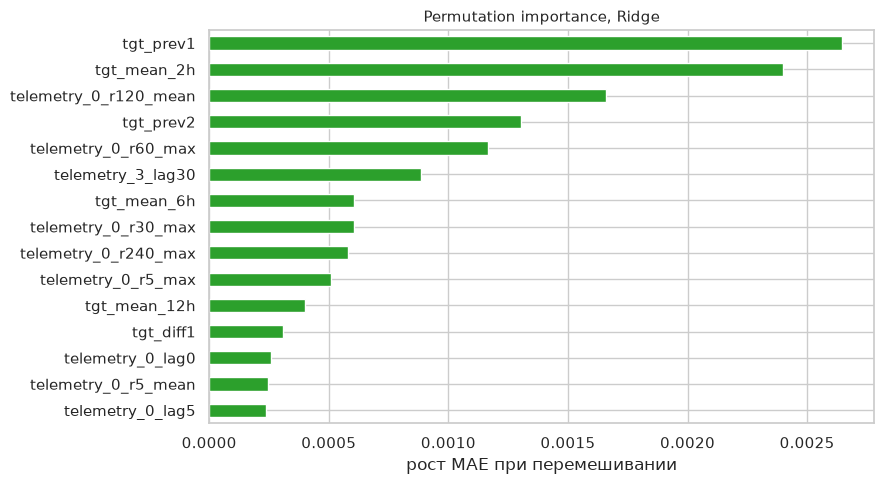

Топ-15 по permutation importance:


,importance
tgt_prev1,0.0026
tgt_mean_2h,0.0024
telemetry_0_r120_mean,0.0017
tgt_prev2,0.0013
telemetry_0_r60_max,0.0012
telemetry_3_lag30,0.0009
tgt_mean_6h,0.0006
telemetry_0_r30_max,0.0006
telemetry_0_r240_max,0.0006
telemetry_0_r5_max,0.0005


In [19]:
# Важность признаков: permutation importance и SHAP для ExtraTrees.
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_ridge, X_test_sel, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=12, random_state=RANDOM_STATE, n_jobs=-1,
)
perm_series = pd.Series(perm.importances_mean, index=selected_cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
perm_series.head(15).iloc[::-1].plot.barh(ax=ax, color="tab:green")
ax.set_title("Permutation importance, Ridge")
ax.set_xlabel("рост MAE при перемешивании")
plt.tight_layout()
plt.show()

print("Топ-15 по permutation importance:")
display(perm_series.head(15).to_frame("importance").round(4))

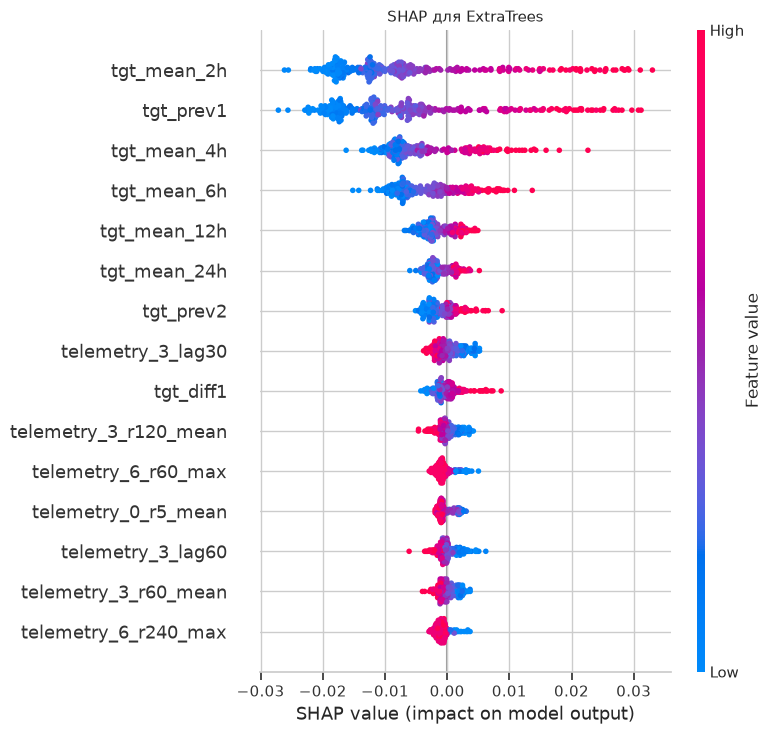

Топ-15 по |SHAP|:


,mean |SHAP|
tgt_mean_2h,0.0129
tgt_prev1,0.0126
tgt_mean_4h,0.0070
tgt_mean_6h,0.0052
tgt_mean_12h,0.0026
tgt_mean_24h,0.0020
tgt_prev2,0.0019
telemetry_3_lag30,0.0016
tgt_diff1,0.0013
telemetry_3_r120_mean,0.0012


In [20]:
import shap

explainer = shap.TreeExplainer(extra_trees)
shap_values = explainer.shap_values(X_test_sel)
if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap.summary_plot(shap_values, X_test_sel, max_display=15, show=False)
plt.title("SHAP для ExtraTrees")
plt.tight_layout()
plt.show()

shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0), index=selected_cols
).sort_values(ascending=False)
print("Топ-15 по |SHAP|:")
display(shap_importance.head(15).to_frame("mean |SHAP|").round(4))

In [21]:
# AIC/BIC для линейных OLS-моделей с разным числом признаков + оценка на тесте.
import statsmodels.api as sm

ic_rows = []
for k in (20, 40, 80, 120):
    selector = SelectKBest(score_func=f_regression, k=k).fit(X_train, y_train)
    cols_k = X_train.columns[selector.get_support()]
    X_tr = sm.add_constant(X_train[cols_k].astype(float))
    X_te = sm.add_constant(X_test[cols_k].astype(float), has_constant="add")
    ols = sm.OLS(y_train.astype(float), X_tr).fit()
    pred = ols.predict(X_te)
    ic_rows.append({
        "k признаков": k,
        "AIC": ols.aic,
        "BIC": ols.bic,
        "MAE test": mean_absolute_error(y_test, pred),
        "WAPE test, %": wape(y_test, pred) * 100,
    })

ic_df = pd.DataFrame(ic_rows).set_index("k признаков")
display(ic_df.round(4))

,AIC,BIC,MAE test,"WAPE test, %"
k признаков,,,,
20,-4121.5320,-4006.4430,0.0531,25.3121
40,-4164.7731,-3940.0755,0.0518,24.7115
80,-4148.6051,-3704.6904,0.0509,24.2615
120,-4131.5112,-3468.3794,0.0509,24.2522


In [22]:
# Итоговая таблица и сохранение прогнозов лучшей модели.
final = metrics_df.copy()
final["Direction acc."] = pd.Series(direction)
display(final.round(4).sort_values("WAPE, %"))

prediction_table = pd.DataFrame({
    "datetime": y_test.index,
    "target": y_test.to_numpy(),
    "prediction_best": best_pred,
    "prediction_ridge": predictions["Ridge (CV)"],
    "prediction_hgb": predictions["HistGradientBoosting"],
    "prediction_extra_trees": predictions["ExtraTrees"],
})
prediction_table.to_csv("predictions_test.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")
print("Лучшая модель по WAPE:", best_name)
print("Файл predictions_test.csv сохранён.")

,MAE,RMSE,"MAPE, %","WAPE, %","fit, сек",Direction acc.
Ridge (CV),0.0518,0.0667,28.4807,24.6868,0.0521,0.6887
HistGradientBoosting,0.0524,0.0680,27.7238,24.9705,12.3991,0.7086
ExtraTrees,0.0537,0.0684,29.8767,25.6191,4.9433,0.7119
Скользящее среднее,0.0554,0.0746,27.9104,26.3972,0.0000,0.5993
Persistence,0.0595,0.0801,29.7174,28.3682,0.0000,0.0000


Лучшая модель по WAPE: Ridge (CV)
Файл predictions_test.csv сохранён.


### Выводы по 2.3

- Лучший результат на тесте показывает **Ridge-регрессия** с отбором признаков:
  MAE ≈ 0.052, RMSE ≈ 0.067, MAPE ≈ 28%, WAPE ≈ 24.7%. Относительно persistence
  (WAPE ≈ 28.4%) ошибка снижается примерно на 13%.
- Деревья и бустинг не дают устойчивого выигрыша: сигнал в телеметрии слабый и шумный,
  а размеченных точек всего 1773. Это ожидаемо для лабораторных данных с высоким
  шумом измерений.
- Остатки ненормальны (Jarque-Bera, p < 0.001) и гетероскедастичны (Breusch-Pagan,
  p < 0.001); значимой автокорреляции остатков на лагах 6 и 12 не обнаружено
  (Ljung-Box, p = 0.16 и 0.41). Модель отслеживает медленный уровень, но не объясняет
  все быстрые колебания.
- Permutation importance и SHAP подтверждают: главный вклад дают лаги и скользящие средние
  target, затем `telemetry_0`, `telemetry_3` и `telemetry_6`. Физически это можно трактовать
  как инерцию теплового режима и чувствительность концентрации к текущим параметрам печи.
- AIC и BIC для OLS минимальны при 40 признаках; дальнейшее расширение модели ухудшает
  BIC. Это аргумент в пользу компактного отбора признаков.

## 2.4. Документирование и интерпретация

### Итоговый пайплайн

1. Дедупликация и минутная сетка телеметрии, интерполяция коротких пропусков.
2. Синхронизация target с телеметрией по времени; исключение текущего замера из признаков.
3. Генерация лагов, скользящих статистик, приращений, календарных и target-признаков.
4. Отбор признаков по F-тесту; Ridge как основная модель, деревья и бустинг для сравнения.
5. Оценка MAE/RMSE/MAPE/WAPE, направления изменения, остатков и важности признаков.

### Практические выводы

- Виртуальный датчик даёт оценку концентрации без ожидания лаборатории, но его точность
  ограничена шумом лабораторных измерений и слабой мгновенной связью с телеметрией.
- Основной резерв улучшения - больше размеченных данных, более частая лабораторная
  выборка и дополнительные режимные признаки (расход, температура, состав сырья).
- Для внедрения нужен мониторинг: контроль дрейфа телеметрии, переобучение на новых
  замерах, доверительные интервалы и ручная проверка при выходе за область обучающих данных.

### Ограничения

- Тестовая выборка короткая (318 замеров), поэтому метрики чувствительны к отдельным
  выбросам.
- Признаки target используют предыдущие лабораторные значения; при длительном пропуске
  замеров качество падает.
- Модель обучена на одном режиме печи; перенос на другой режим требует валидации.